# 07 - Decision Tree Hyperparameter Tuning


Best max_depth for Decision Tree: 5


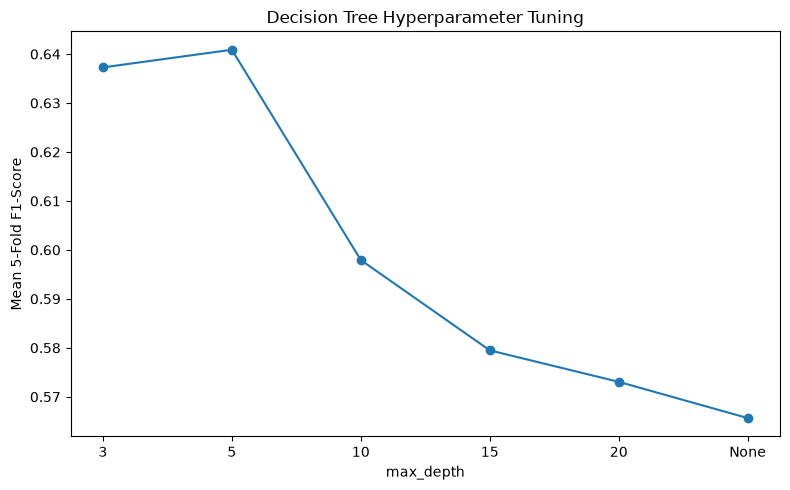

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('online_shoppers_intention.csv')
df = df.drop_duplicates().copy()
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Total_Duration'] = (
    df['Administrative_Duration'] +
    df['Informational_Duration'] +
    df['ProductRelated_Duration']
)

df = pd.get_dummies(
    df,
    columns=['Month', 'VisitorType'],
    drop_first=True,
    dtype=int
)

X = df.drop('Revenue', axis=1)
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

depth_values = [3, 5, 10, 15, 20, None]
dt_scores = []

for depth in depth_values:
    score = cross_val_score(
        DecisionTreeClassifier(max_depth=depth, random_state=42),
        X_train,
        y_train,
        cv=5,
        scoring='f1'
    ).mean()
    dt_scores.append(score)

best_depth = depth_values[np.argmax(dt_scores)]
print('Best max_depth for Decision Tree:', best_depth)

labels = ['3', '5', '10', '15', '20', 'None']

plt.figure(figsize=(8, 5))
plt.plot(labels, dt_scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Mean 5-Fold F1-Score')
plt.title('Decision Tree Hyperparameter Tuning')
plt.tight_layout()
plt.show()
